# Phase 10 — Stress Testing

**Advanced Equity Portfolio Risk Management Platform**
**QFI Internship — Team 2 (Market Risk)** · *Submitted by: Atharv Pratap Singh Chauhan*

---

## Objective

VaR answers *"how bad is a normal bad day?"*. Stress testing answers the complementary question regulators actually lose sleep over: *"what happens on an abnormal day the model has never priced?"*. Phases 4–9 calibrated and ranked day-to-day VaR; Phase 10 pushes the **current** equal-weighted book through deliberately extreme states and measures the loss directly.

| Family | Scenarios |
|---|---|
| **Historical replay** | In-sample worst windows + documented out-of-sample crises (2008 GFC, COVID-2020) applied via market beta |
| **Hypothetical market** | Instantaneous index shocks −5% / −10% / −20% / −30% |
| **Volatility shock** | Conditional volatility doubles |
| **Correlation shock** | All pairwise correlations spike to 1 (diversification collapses) |
| **Sector shock** | Mega-cap tech/growth sleeve sold off in isolation |
| **Reverse stress** | Solve for the shock that produces a target loss |

Every loss is reported in currency, as a % of NAV, and against the headline **99% / 250-day** VaR so the reader sees how many "normal bad days" each scenario equals.

## 1. Methodology

**Current book.** The portfolio is equal-weighted ($w_i=1/N$, rebalanced monthly in Phase 3) across $N=10$ large-cap US equities, benchmark S&P 500. Stress is applied to the latest NAV from Phase 3.

**Market-beta overlay.** For an instantaneous index move $s$, each stock moves $\approx\beta_i s$ (CAPM first order) where $\beta_i$ is the OLS slope of stock returns on benchmark returns. Portfolio loss is
$$\Delta V = \text{NAV}\cdot\sum_i w_i\beta_i\,s = \text{NAV}\cdot\beta_p\,s,\qquad \beta_p=\sum_i w_i\beta_i.$$
This is how out-of-sample crises (2008, COVID — before our data begins) are mapped onto today's holdings: via their documented S&P drawdowns.

**Volatility shock.** The current one-day portfolio volatility $\sigma_p=\sqrt{w^\top\Sigma w}$ (from the trailing-250-day covariance) is doubled, and parametric-normal VaR $z_c\,\sigma_p\,\text{NAV}$ is recomputed.

**Correlation shock.** Marginal volatilities are held but every pairwise correlation is set to 1, so $\sigma_p^{\text{spike}}=\sum_i w_i\sigma_i$ — the fully-undiversified book. The gap $\sigma_p^{\text{spike}}-\sigma_p$ is the diversification benefit that evaporates in a crisis.

**Reverse stress test.** Instead of fixing the shock and reading the loss, we fix a loss (the 99% VaR, 10% of NAV, 20% of NAV) and solve for the index move $s=-\,\text{loss}/(\beta_p\,\text{NAV})$ that causes it — the question a board asks: *"how far does the market fall before we lose a fifth of the fund?"*

In [1]:
from __future__ import annotations
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PALETTE = {"ink":"#1B2A41","muted":"#8C99A6","profit":"#2E7D68","loss":"#B03A2E",
           "HS":"#E08A2E","EWMA":"#6A2C91","GARCH":"#1F6F8B","GJR":"#9B2242",
           "green":"#2E7D68","amber":"#E0A52E","red":"#B03A2E","light":"#E9EDF2"}
sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({"figure.dpi":110,"savefig.dpi":200,"savefig.bbox":"tight",
    "figure.facecolor":"white","axes.facecolor":"white","axes.edgecolor":PALETTE["muted"],
    "axes.titlecolor":PALETTE["ink"],"axes.titleweight":"bold","axes.titlesize":14,
    "axes.labelsize":11,"axes.titlepad":12,"grid.color":"#E3E7EB","grid.linewidth":0.8,
    "xtick.labelsize":9,"ytick.labelsize":9,"legend.fontsize":9,"font.family":"DejaVu Sans"})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)
CURRENCY="₹"; HEADLINE_W=250; HEADLINE_C=0.99
OUT=Path("outputs"); OUT.mkdir(parents=True, exist_ok=True); (OUT/"charts").mkdir(exist_ok=True)
def money(x): return f"{CURRENCY}{x:,.0f}"
def pct(x,dp=2): return "n/a" if not np.isfinite(x) else f"{100*x:.{dp}f}%"
print("Phase 10 stress-testing config ready.")


Phase 10 stress-testing config ready.


## 2. Load the book and estimate its risk factors

We read the Phase 2 clean return matrix, the benchmark, and the Phase 3 NAV, then estimate per-stock betas (OLS on benchmark returns), the trailing-250-day covariance, and the current portfolio volatility. The headline VaR from Phases 4–9 is loaded as the yardstick against which stress losses are measured.

In [2]:
def locate(name):
    for p in [Path(name), OUT/name, Path("..")/name, Path("..")/"outputs"/name]:
        if p.exists(): return p
    return None

rets = pd.read_csv(locate("Clean_Return_Matrix.csv"), index_col=0, parse_dates=True)
bench_px = pd.read_csv(locate("00003069-Benchmark_prices.csv"), index_col=0, parse_dates=True).sort_index()
bench_ret = np.log(bench_px/bench_px.shift(1)).iloc[:,0].reindex(rets.index).dropna()
port = pd.read_csv(locate("Portfolio_Construction.csv"), index_col=0, parse_dates=True)
NAV = float(port["Value"].iloc[-1])

tickers = list(rets.columns); N = len(tickers)
w = pd.Series(1.0/N, index=tickers)                       # current equal weights
common = rets.index.intersection(bench_ret.index)
betas = pd.Series({t: np.polyfit(bench_ret.reindex(common).values,
                                 rets[t].reindex(common).values, 1)[0] for t in tickers})
beta_p = float((w*betas).sum())

recent = rets.tail(250)
Sigma = recent.cov()                                      # trailing-250d daily covariance
sig_i = recent.std()                                      # per-stock daily vol
sig_p = float(np.sqrt(w.values @ Sigma.values @ w.values))        # diversified port vol
sig_p_fc = float((w*sig_i).sum())                                 # fully-correlated port vol

# headline VaR yardstick: pull GJR (best Phase-9 model) 99%/250d, fall back to HS
def headline_var():
    for pre,f in [("GJR","GJR_GARCH_Scaled_VaR.csv"),("GARCH","GARCH_Scaled_VaR.csv"),
                  ("EWMA","EWMA_Scaled_VaR.csv")]:
        p = locate(f)
        if p is None: continue
        df = pd.read_csv(p, index_col=0, parse_dates=True)
        col = f"{pre}_VaR_{HEADLINE_W}d_{int(HEADLINE_C*100)}"
        if col in df: return float(df[col].dropna().iloc[-1]), pre
    return np.nan, "n/a"
VAR_HEADLINE, VAR_SRC = headline_var()

SECTORS = {"AAPL":"Tech/Growth","AMZN":"Tech/Growth","GOOGL":"Tech/Growth","META":"Tech/Growth",
           "MSFT":"Tech/Growth","NVDA":"Tech/Growth","TSLA":"Tech/Growth",
           "JPM":"Financials","XOM":"Energy","UNH":"Healthcare"}
TECH = [t for t in tickers if SECTORS.get(t)=="Tech/Growth"]

print(f"NAV {money(NAV)} | N={N} | portfolio beta {beta_p:.3f}")
print(f"Current 1-day vol: diversified {pct(sig_p)} vs fully-correlated {pct(sig_p_fc)} "
      f"(diversification cushion {pct(sig_p_fc-sig_p)})")
print(f"Headline VaR ({HEADLINE_C:.1%}, {HEADLINE_W}d, {VAR_SRC}): {money(VAR_HEADLINE)}")
display(betas.rename("Beta").to_frame().T.style.format("{:.2f}"))


NAV ₹2,995,852 | N=10 | portfolio beta 1.214
Current 1-day vol: diversified 1.02% vs fully-correlated 1.95% (diversification cushion 0.92%)
Headline VaR (99.0%, 250d, GJR): ₹120,039


,AAPL,AMZN,GOOGL,JPM,META,MSFT,NVDA,TSLA,UNH,XOM
Beta,1.16,1.40,1.24,0.82,1.48,1.11,2.01,1.97,0.47,0.47


## 3. Historical scenario replay

Two kinds of history. **In-sample** episodes are replayed from the portfolio's *own realised returns* over the crisis window — the true loss the book would have taken. **Out-of-sample** crises that predate our 2020–2026 data (the 2008 GFC and the Feb–Mar 2020 COVID crash) are mapped onto today's holdings through the portfolio beta using their documented S&P 500 drawdowns.

In [3]:
port_ret = port["Return"].astype(float)

# in-sample episodes: cumulative portfolio return over the window (actual data)
IN_SAMPLE = {
    "2022 Inflation / rate shock":   ("2022-01-01","2022-10-14"),
    "2023 Banking stress (SVB)":     ("2023-03-08","2023-03-15"),
    "2024 Aug carry unwind":         ("2024-07-31","2024-08-07"),
    "2025 Tariff shock":             ("2025-04-02","2025-04-10"),
}
rows = []
for name,(s,e) in IN_SAMPLE.items():
    seg = port_ret.loc[s:e]
    if len(seg)==0: continue
    cum = float(np.expm1(np.log1p(seg).sum()))            # compounded window return
    rows.append({"Scenario":name,"Type":"In-sample replay","Window":f"{seg.index[0]:%d-%b-%y}→{seg.index[-1]:%d-%b-%y}",
                 "Shock":pct(cum),"Loss":-cum*NAV,"Loss_pctNAV":-cum,"xVaR":(-cum*NAV)/VAR_HEADLINE})

# worst realised windows anywhere in the sample
for k in (1,5,10):
    roll = np.expm1(np.log1p(port_ret).rolling(k).sum())
    worst = roll.min(); end = roll.idxmin()
    rows.append({"Scenario":f"Worst realised {k}-day","Type":"In-sample replay",
                 "Window":f"ending {end:%d-%b-%y}","Shock":pct(worst),
                 "Loss":-worst*NAV,"Loss_pctNAV":-worst,"xVaR":(-worst*NAV)/VAR_HEADLINE})

# out-of-sample crises via documented S&P drawdown and portfolio beta
OUT_SAMPLE = {"2008 GFC (acute Sep–Nov)":-0.30, "2008 GFC (peak-to-trough)":-0.568,
              "COVID crash (Feb–Mar 2020)":-0.339, "Black Monday 1987 (1 day)":-0.204}
for name,idx_shock in OUT_SAMPLE.items():
    port_shock = beta_p*idx_shock                         # beta overlay
    rows.append({"Scenario":name,"Type":"Beta overlay","Window":"documented S&P move",
                 "Shock":pct(port_shock),"Loss":-port_shock*NAV,"Loss_pctNAV":-port_shock,
                 "xVaR":(-port_shock*NAV)/VAR_HEADLINE})

hist = pd.DataFrame(rows)
hist.to_csv(OUT/"Stress_Historical.csv", index=False)
display(hist[["Scenario","Type","Window","Shock","Loss","Loss_pctNAV","xVaR"]].style
    .format({"Loss":money,"Loss_pctNAV":"{:.1%}","xVaR":"{:.1f}×"})
    .background_gradient(subset=["xVaR"], cmap="Reds"))


,Scenario,Type,Window,Shock,Loss,Loss_pctNAV,xVaR
0,2022 Inflation / rate shock,In-sample replay,03-Jan-22→14-Oct-22,-32.77%,"₹981,755",32.8%,8.2×
1,2023 Banking stress (SVB),In-sample replay,08-Mar-23→15-Mar-23,0.03%,₹-940,-0.0%,-0.0×
2,2024 Aug carry unwind,In-sample replay,31-Jul-24→07-Aug-24,-5.42%,"₹162,258",5.4%,1.4×
3,2025 Tariff shock,In-sample replay,02-Apr-25→10-Apr-25,-7.96%,"₹238,602",8.0%,2.0×
4,Worst realised 1-day,In-sample replay,ending 13-Sep-22,-5.44%,"₹162,942",5.4%,1.4×
5,Worst realised 5-day,In-sample replay,ending 14-Jun-22,-11.61%,"₹347,735",11.6%,2.9×
6,Worst realised 10-day,In-sample replay,ending 16-Jun-22,-14.19%,"₹425,213",14.2%,3.5×
7,2008 GFC (acute Sep–Nov),Beta overlay,documented S&P move,-36.42%,"₹1,091,153",36.4%,9.1×
8,2008 GFC (peak-to-trough),Beta overlay,documented S&P move,-68.96%,"₹2,065,916",69.0%,17.2×
9,COVID crash (Feb–Mar 2020),Beta overlay,documented S&P move,-41.16%,"₹1,233,003",41.2%,10.3×


### Chart 1 — Stress losses ranked against VaR

Every scenario as a multiple of the headline 99% VaR. The dashed line at 1× marks a loss equal to a single normal bad day; the bars show how many such days each stress event compresses into one.

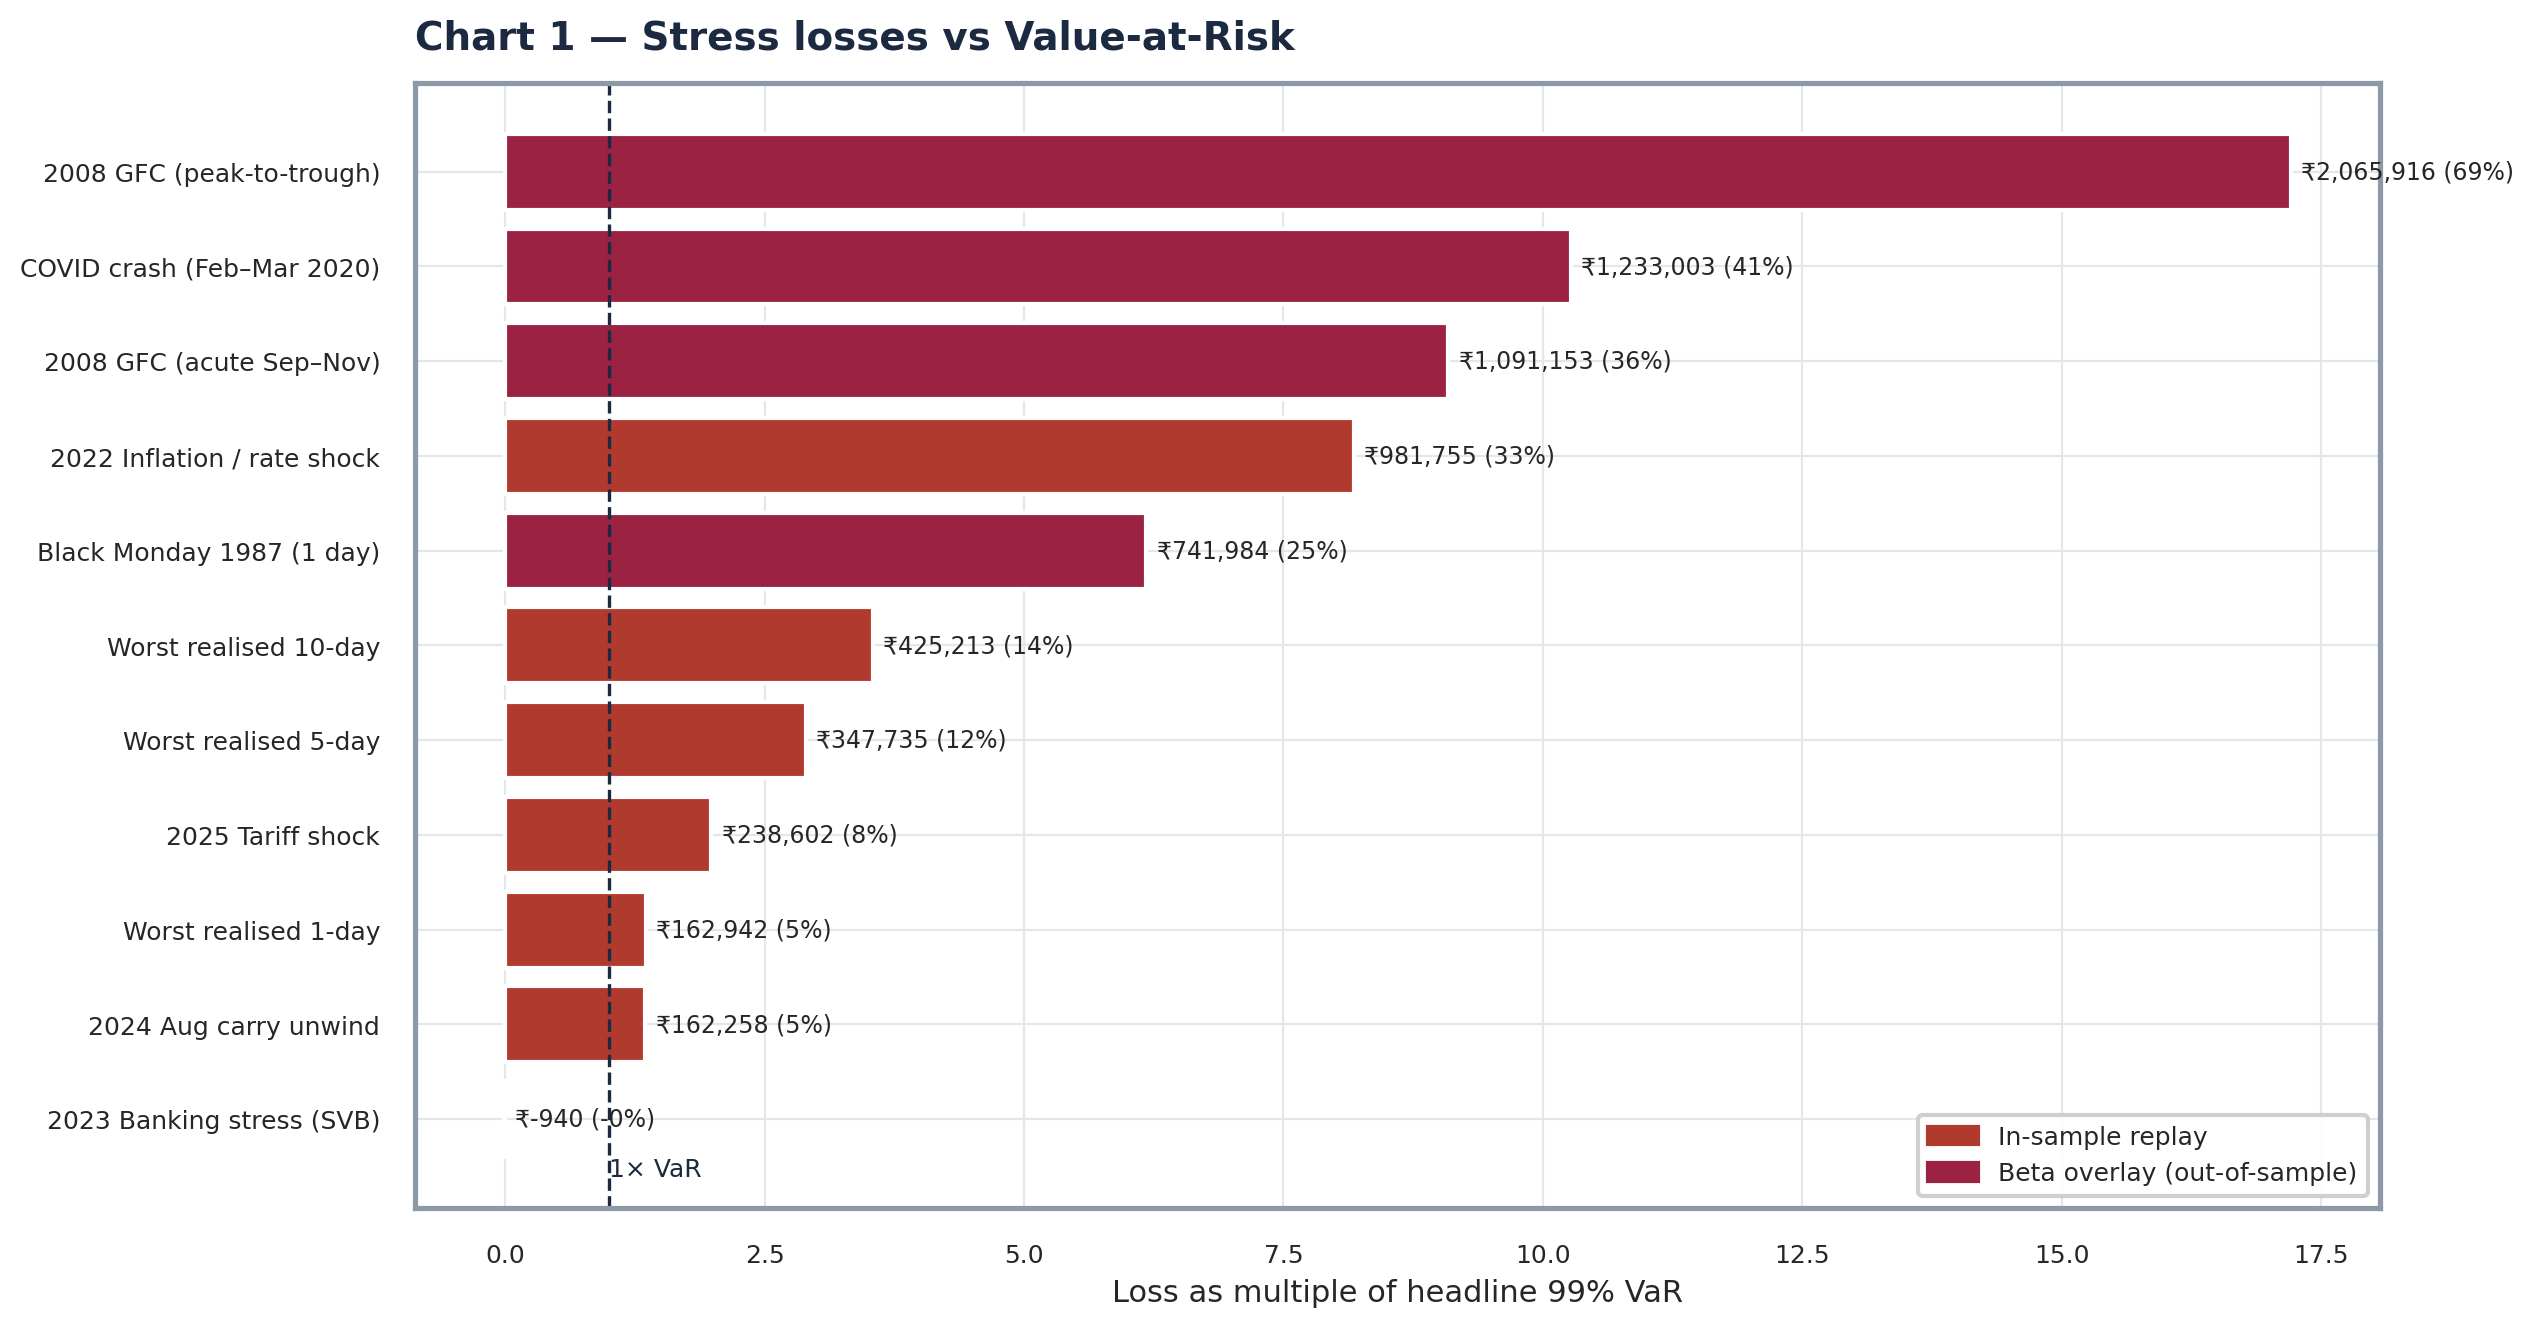

In [4]:
d = hist.sort_values("xVaR")
colors = [PALETTE["GJR"] if t=="Beta overlay" else PALETTE["loss"] for t in d["Type"]]
fig, ax = plt.subplots(figsize=(13, 7))
ax.barh(d["Scenario"], d["xVaR"], color=colors, edgecolor="white")
ax.axvline(1.0, color=PALETTE["ink"], ls="--", lw=1.2)
ax.text(1.0, -0.6, "1× VaR", color=PALETTE["ink"], fontsize=9)
for i,(_,r) in enumerate(d.iterrows()):
    ax.text(r["xVaR"]+0.1, i, f"{money(r['Loss'])} ({pct(r['Loss_pctNAV'],0)})", va="center", fontsize=8.5)
ax.set_xlabel(f"Loss as multiple of headline {HEADLINE_C:.0%} VaR")
ax.set_title("Chart 1 — Stress losses vs Value-at-Risk", loc="left")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETTE["loss"],label="In-sample replay"),
                   Patch(color=PALETTE["GJR"],label="Beta overlay (out-of-sample)")], loc="lower right")
fig.tight_layout(); fig.savefig(OUT/"charts/10_stress_vs_var.png", facecolor="white"); plt.show()


## 4. Hypothetical market shocks

Instantaneous index moves mapped to the book through $\beta_p$. These are not tied to any dated event — they answer *"if the market gapped −X% at the open, what would we lose?"*.

,Index_shock,Portfolio_move,Loss,Loss_pctNAV,xVaR,Residual_NAV
0,-5%,-6.1%,"₹181,859",6.1%,1.5×,"₹2,813,993"
1,-10%,-12.1%,"₹363,718",12.1%,3.0×,"₹2,632,135"
2,-20%,-24.3%,"₹727,435",24.3%,6.1×,"₹2,268,417"
3,-30%,-36.4%,"₹1,091,153",36.4%,9.1×,"₹1,904,699"


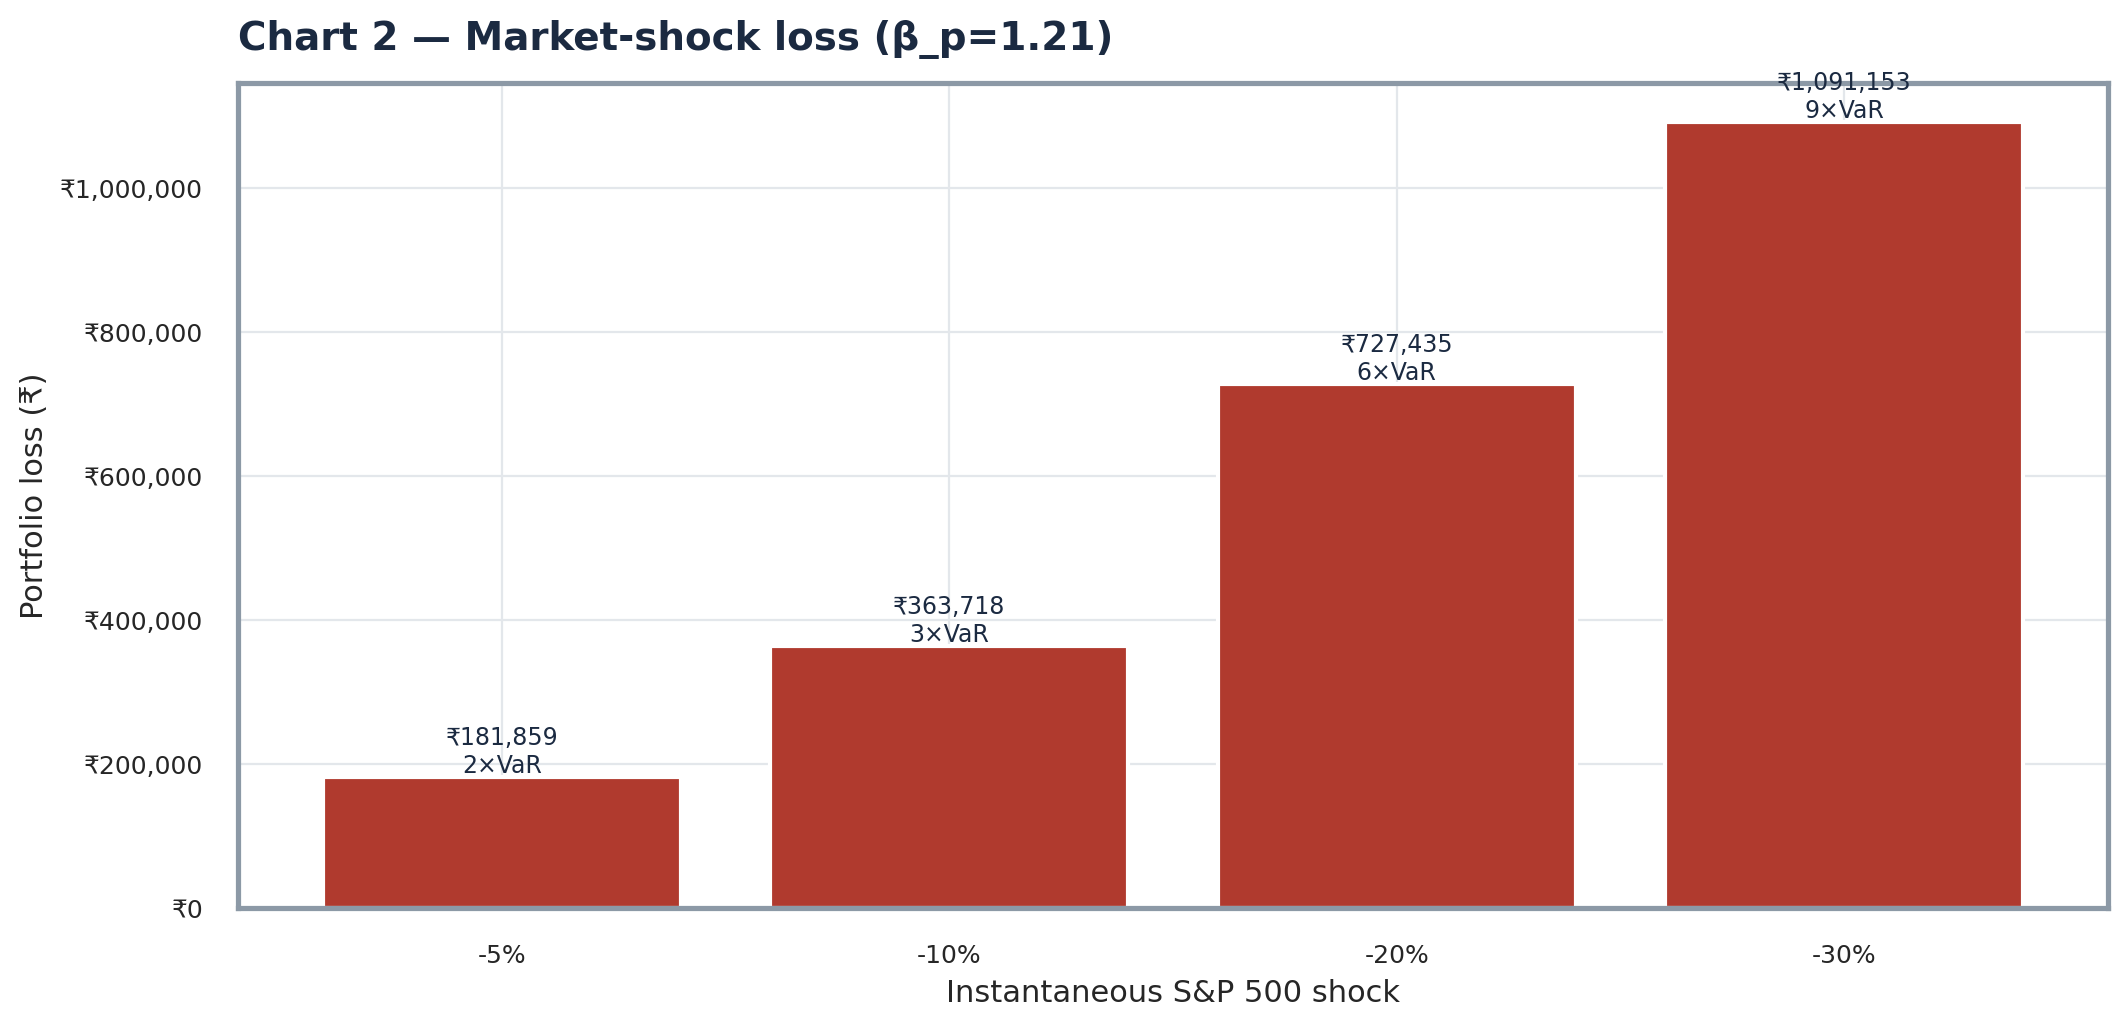

In [5]:
grid = [-0.05,-0.10,-0.20,-0.30]
mkt = pd.DataFrame({"Index_shock":grid})
mkt["Portfolio_move"] = beta_p*mkt["Index_shock"]
mkt["Loss"] = -mkt["Portfolio_move"]*NAV
mkt["Loss_pctNAV"] = -mkt["Portfolio_move"]
mkt["xVaR"] = mkt["Loss"]/VAR_HEADLINE
mkt["Residual_NAV"] = NAV + mkt["Portfolio_move"]*NAV
display(mkt.style.format({"Index_shock":"{:.0%}","Portfolio_move":"{:.1%}","Loss":money,
    "Loss_pctNAV":"{:.1%}","xVaR":"{:.1f}×","Residual_NAV":money}))

fig, ax = plt.subplots(figsize=(11,5.5))
ax.bar([f"{s:.0%}" for s in grid], mkt["Loss"].values, color=PALETTE["loss"], edgecolor="white")
for i,s in enumerate(grid):
    ax.text(i, mkt["Loss"].iloc[i], f"\n{money(mkt['Loss'].iloc[i])}\n{mkt['xVaR'].iloc[i]:.0f}×VaR",
            ha="center", va="bottom", fontsize=8.5, color=PALETTE["ink"])
ax.set_xlabel("Instantaneous S&P 500 shock"); ax.set_ylabel(f"Portfolio loss ({CURRENCY})")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter(CURRENCY+"{x:,.0f}"))
ax.set_title(f"Chart 2 — Market-shock loss (β_p={beta_p:.2f})", loc="left")
fig.tight_layout(); fig.savefig(OUT/"charts/10_market_shocks.png", facecolor="white"); plt.show()


## 5. Volatility, correlation and sector shocks

,Scenario,VaR,xBase
0,Base parametric VaR,"₹71,293",1.00×
1,Volatility doubles,"₹142,586",2.00×
2,Correlations → 1,"₹135,730",1.90×


,Scenario,Loss,Loss_pctNAV,xVaR
0,Tech/Growth sleeve -15%,"₹314,564",10.5%,2.6×
1,Tech/Growth sleeve -25%,"₹524,274",17.5%,4.4×


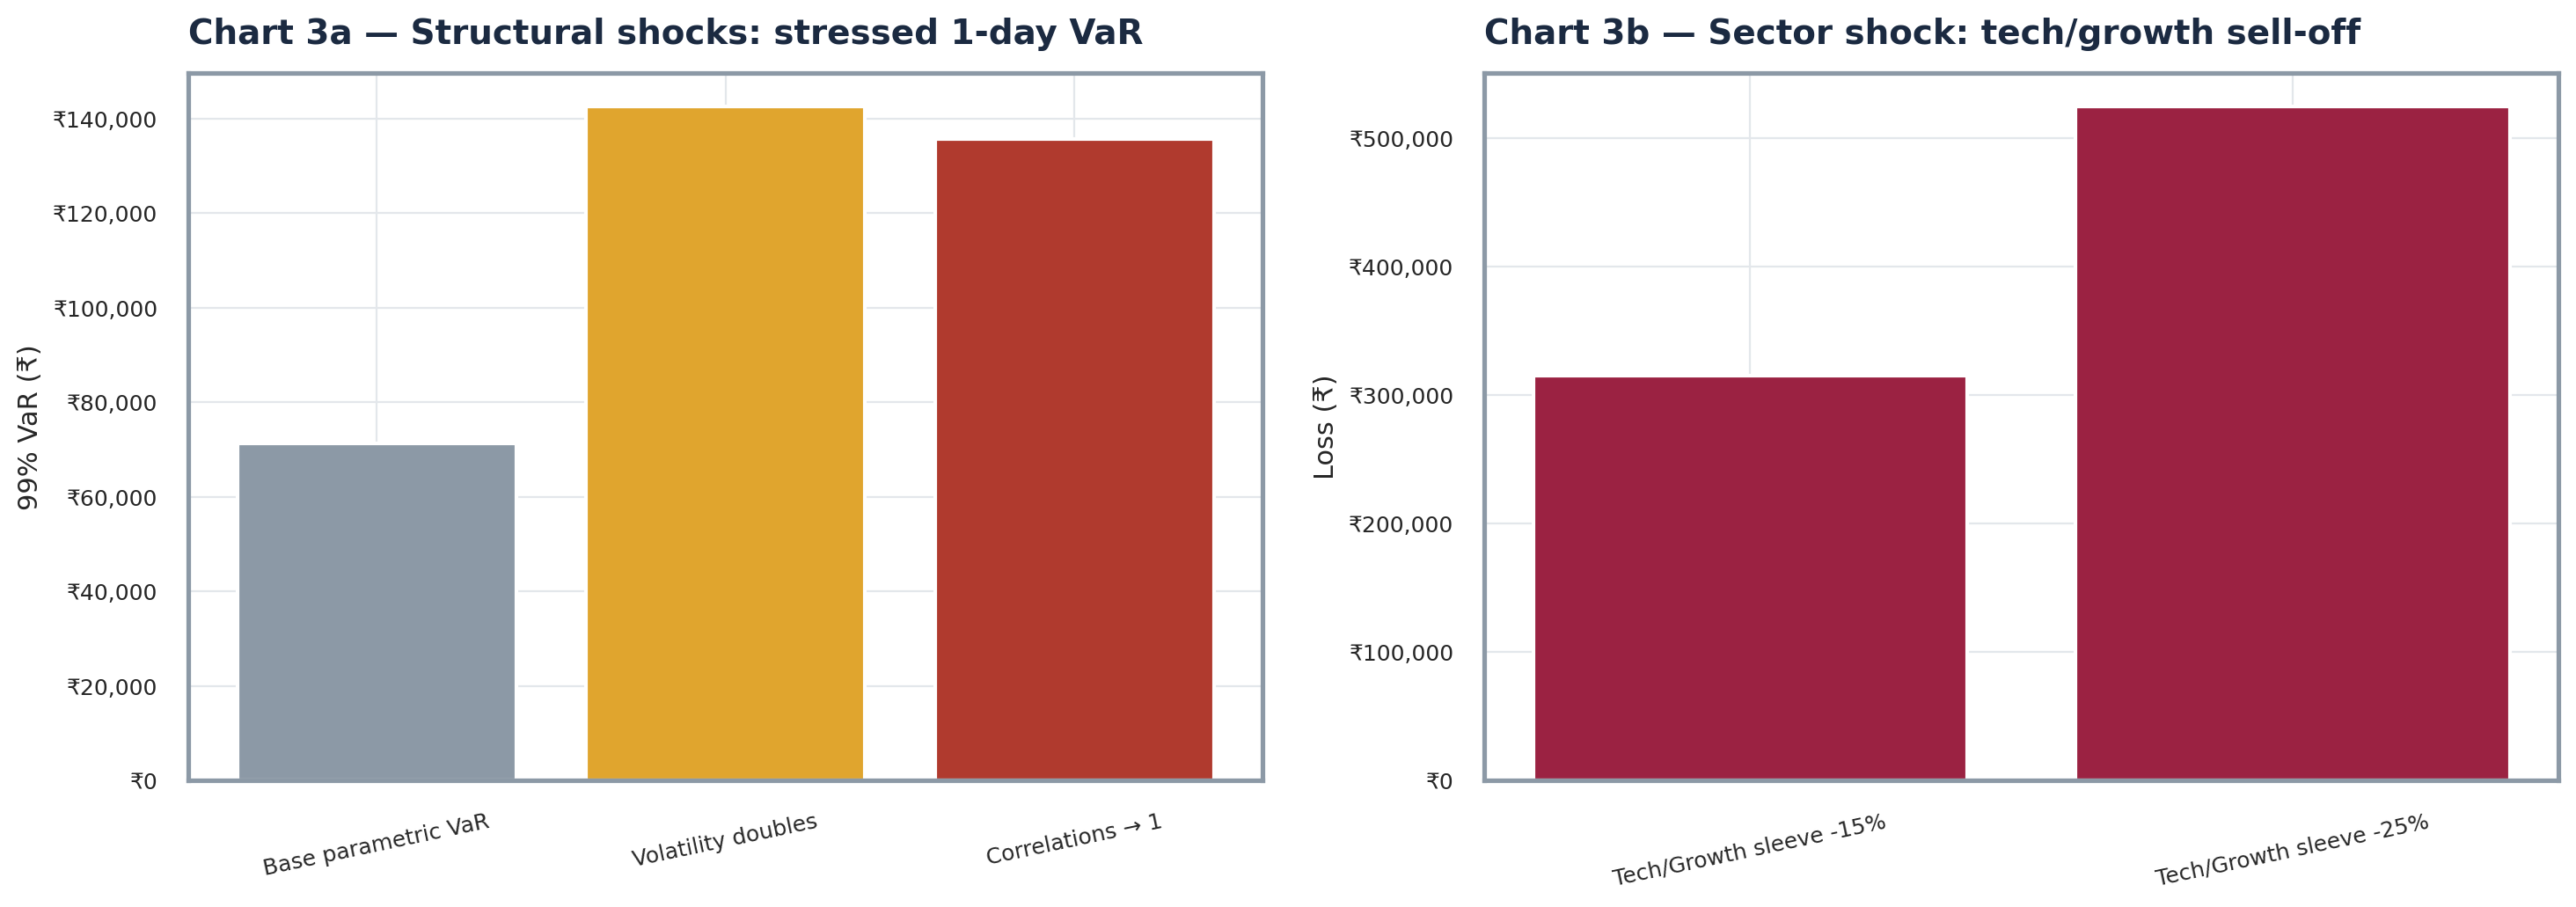

In [6]:
z = stats.norm.ppf(HEADLINE_C)
base_var   = z*sig_p*NAV
vol2_var   = z*(2*sig_p)*NAV                       # conditional vol doubles
corr_var   = z*sig_p_fc*NAV                        # all correlations -> 1

# sector shock: tech/growth sleeve -15% and -25%, rest unmoved
sec_rows = []
for shk in (-0.15,-0.25):
    move = sum(w[t]*shk for t in TECH)             # only tech names move
    sec_rows.append({"Scenario":f"Tech/Growth sleeve {shk:.0%}","Loss":-move*NAV,
                     "Loss_pctNAV":-move,"xVaR":(-move*NAV)/VAR_HEADLINE})
sector = pd.DataFrame(sec_rows)

structural = pd.DataFrame([
    {"Scenario":"Base parametric VaR","VaR":base_var,"xBase":1.0},
    {"Scenario":"Volatility doubles","VaR":vol2_var,"xBase":vol2_var/base_var},
    {"Scenario":"Correlations → 1","VaR":corr_var,"xBase":corr_var/base_var},
])
display(structural.style.format({"VaR":money,"xBase":"{:.2f}×"}))
display(sector.style.format({"Loss":money,"Loss_pctNAV":"{:.1%}","xVaR":"{:.1f}×"}))

fig, (a1,a2) = plt.subplots(1,2,figsize=(15,5.5))
a1.bar(structural["Scenario"], structural["VaR"], color=[PALETTE["muted"],PALETTE["amber"],PALETTE["red"]], edgecolor="white")
a1.set_title("Chart 3a — Structural shocks: stressed 1-day VaR", loc="left")
a1.set_ylabel(f"99% VaR ({CURRENCY})"); a1.yaxis.set_major_formatter(mticker.StrMethodFormatter(CURRENCY+"{x:,.0f}"))
a1.tick_params(axis="x", labelrotation=12)
a2.bar(sector["Scenario"], sector["Loss"], color=PALETTE["GJR"], edgecolor="white")
a2.set_title("Chart 3b — Sector shock: tech/growth sell-off", loc="left")
a2.set_ylabel(f"Loss ({CURRENCY})"); a2.yaxis.set_major_formatter(mticker.StrMethodFormatter(CURRENCY+"{x:,.0f}"))
a2.tick_params(axis="x", labelrotation=12)
fig.tight_layout(); fig.savefig(OUT/"charts/10_structural_sector.png", facecolor="white"); plt.show()


## 6. Reverse stress test

Fix the loss, solve for the market move that causes it. $s=-\,\text{loss}/(\beta_p\cdot\text{NAV})$.

In [7]:
targets = {"= headline 99% VaR":VAR_HEADLINE, "= 10% of NAV":0.10*NAV,
           "= 20% of NAV":0.20*NAV, "= 33% of NAV":0.33*NAV}
rev = pd.DataFrame([{"Loss trigger":k,"Loss":v,"Required S&P shock":-(v/(beta_p*NAV))}
                    for k,v in targets.items()])
rev.to_csv(OUT/"Stress_Reverse.csv", index=False)
display(rev.style.format({"Loss":money,"Required S&P shock":"{:.1%}"}))


,Loss trigger,Loss,Required S&P shock
0,= headline 99% VaR,"₹120,039",-3.3%
1,= 10% of NAV,"₹299,585",-8.2%
2,= 20% of NAV,"₹599,170",-16.5%
3,= 33% of NAV,"₹988,631",-27.2%


## 7. Executive summary

In [8]:
worst = hist.loc[hist["Loss"].idxmax()]
worst_insample = hist[hist.Type=="In-sample replay"].sort_values("Loss").iloc[-1]
m20 = mkt[mkt.Index_shock==-0.20].iloc[0]
div_cushion = sig_p_fc - sig_p

lines = [f"### Phase 10 verdict — stress profile of the current book\n",
    f"- **Book:** {money(NAV)} across {N} large-cap equities, portfolio beta **{beta_p:.2f}** "
    f"(aggressive — moves ~{beta_p:.0%} of any market shock). Headline {HEADLINE_C:.0%}/{HEADLINE_W}d VaR = {money(VAR_HEADLINE)}.",
    f"- **Worst-case scenario:** {worst['Scenario']} → loss {money(worst['Loss'])} "
    f"({pct(worst['Loss_pctNAV'],0)} of NAV, {worst['xVaR']:.0f}× the headline VaR).",
    f"- **Worst realised episode in-sample:** {worst_insample['Scenario']} "
    f"({worst_insample['Window']}) cost {money(worst_insample['Loss'])} ({pct(worst_insample['Loss_pctNAV'],0)}).",
    f"- **A −20% market gap** would cost {money(m20['Loss'])} ({pct(m20['Loss_pctNAV'],0)} of NAV) — "
    f"about **{m20['xVaR']:.0f}× a normal 99% day**, the clearest illustration that VaR alone understates crisis risk.",
    f"- **Diversification is fragile:** a correlation spike to 1 lifts 1-day VaR from {money(base_var)} to {money(corr_var)} "
    f"(×{corr_var/base_var:.2f}); the {pct(div_cushion)} of daily vol currently saved by diversification "
    f"disappears exactly when it is needed most.",
    f"- **Volatility doubling** alone pushes 1-day VaR to {money(vol2_var)} (×{vol2_var/base_var:.2f}) — "
    f"the regime the GARCH/GJR scaling of Phases 6–7 is built to catch early.",
    f"\n**Reverse stress:** the market would need to fall "
    f"**{pct(abs(rev.iloc[1]['Required S&P shock']),0)}** to cost 10% of NAV and "
    f"**{pct(abs(rev.iloc[2]['Required S&P shock']),0)}** to cost 20% — both well inside the 2008/COVID historical range, "
    f"so these are plausible, not tail-of-tail, outcomes."]
display(Markdown("\n".join(lines)))
print("Exports: Stress_Historical.csv, Stress_Reverse.csv")


### Phase 10 verdict — stress profile of the current book

- **Book:** ₹2,995,852 across 10 large-cap equities, portfolio beta **1.21** (aggressive — moves ~121% of any market shock). Headline 99%/250d VaR = ₹120,039.
- **Worst-case scenario:** 2008 GFC (peak-to-trough) → loss ₹2,065,916 (69% of NAV, 17× the headline VaR).
- **Worst realised episode in-sample:** 2022 Inflation / rate shock (03-Jan-22→14-Oct-22) cost ₹981,755 (33%).
- **A −20% market gap** would cost ₹727,435 (24% of NAV) — about **6× a normal 99% day**, the clearest illustration that VaR alone understates crisis risk.
- **Diversification is fragile:** a correlation spike to 1 lifts 1-day VaR from ₹71,293 to ₹135,730 (×1.90); the 0.92% of daily vol currently saved by diversification disappears exactly when it is needed most.
- **Volatility doubling** alone pushes 1-day VaR to ₹142,586 (×2.00) — the regime the GARCH/GJR scaling of Phases 6–7 is built to catch early.

**Reverse stress:** the market would need to fall **8%** to cost 10% of NAV and **16%** to cost 20% — both well inside the 2008/COVID historical range, so these are plausible, not tail-of-tail, outcomes.

Exports: Stress_Historical.csv, Stress_Reverse.csv


## 8. Limitations

- **First-order beta overlay.** Out-of-sample crises and market shocks assume a constant linear beta and zero idiosyncratic move. In a real crash betas drift toward 1, dispersion explodes, and high-beta names (NVDA, TSLA here) overshoot the linear estimate — so beta-overlay losses are, if anything, *understated* for this growth-tilted book.
- **No non-linearity / no options.** The book is cash equity, so linear shocks are reasonable; a portfolio with convexity (options, leverage, path-dependent payoffs) would need full revaluation, not a beta map.
- **Instantaneous shocks.** Market/vol/correlation scenarios are single-step gaps with no liquidity horizon, no forced deleveraging and no feedback — the realised multi-day loss in a true crisis is usually worse than the one-shot figure.
- **Trailing-250-day risk factors.** Betas, volatilities and correlations are estimated on recent calm-to-normal data; all three understate their own crisis values, which is the standard, conservative-to-acknowledge weakness of any point-in-time stress calibration.
- **Documented drawdowns are point estimates.** The 2008/COVID S&P figures are historical facts applied to today's weights; they are illustrative of magnitude, not a forecast that the *same* names would move identically.